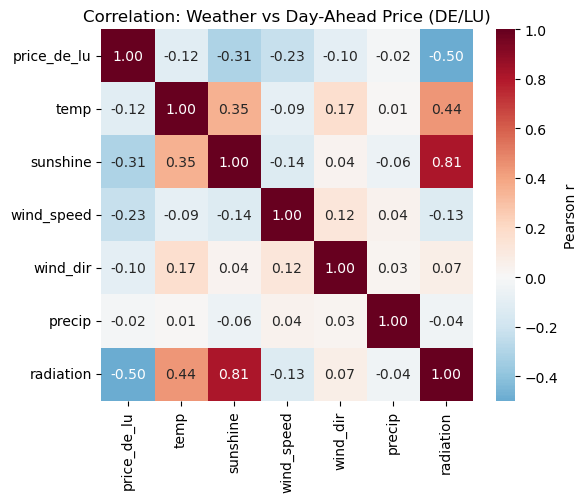


=== Correlation with price_de_lu (ranked by |r|) ===
radiation    -0.4985
sunshine     -0.3068
wind_speed   -0.2324
temp         -0.1179
wind_dir     -0.0958
precip       -0.0188


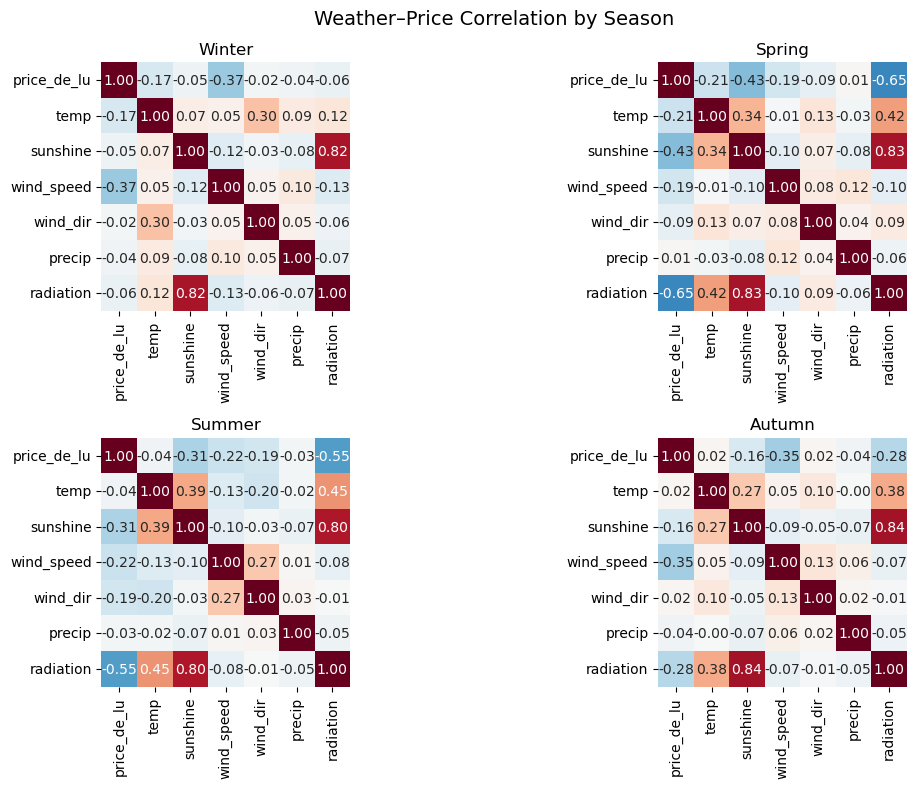

In [11]:
# ==========================================
# Weather — Price Analysis
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- 1. Load Data ----------
file_path = r"C:\Users\Dell\Desktop\Project\Merged.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")

df = df.rename(columns={
    df.columns[0]: 'time',
    df.columns[1]: 'price_de_lu',
    df.columns[2]: 'price_neighbors',
    df.columns[3]: 'temp',
    df.columns[4]: 'sunshine',
    df.columns[5]: 'wind_speed',
    df.columns[6]: 'wind_dir',
    df.columns[7]: 'is_day',
    df.columns[8]: 'precip',
    df.columns[9]: 'radiation',
})

df['time'] = pd.to_datetime(df['time'], errors='coerce')
df = df.dropna(subset=['time']).set_index('time').sort_index()
df = df[~df.index.duplicated(keep='first')]

#print("Total rows:", len(df))
#print("Time range:", df.index.min(), "to", df.index.max())
#print("Columns   :", list(df.columns))

# ---------- 2. Missing value check ----------
#print("\n=== Missing value check ===")
#print(df.isna().mean().round(4) * 100)   # % missing per column

# ---------- 3. Correlation with price ----------
weather_vars = ['temp', 'sunshine', 'wind_speed', 'wind_dir', 'precip', 'radiation']
corr_cols = ['price_de_lu'] + weather_vars
corr = df[corr_cols].corr()

# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation: Weather vs Day-Ahead Price (DE/LU)')
plt.tight_layout()
plt.show()

# Ranked correlation with price
print("\n=== Correlation with price_de_lu (ranked by |r|) ===")
print(corr['price_de_lu'].drop('price_de_lu')
      .sort_values(key=abs, ascending=False)
      .round(4).to_string())

# ---------- 4. Correlation by season ----------
df['month'] = df.index.month
def season(m):
    if m in [12, 1, 2]:   return 'Winter'
    if m in [3, 4, 5]:    return 'Spring'
    if m in [6, 7, 8]:    return 'Summer'
    if m in [9, 10, 11]:  return 'Autumn'
df['season'] = df['month'].apply(season)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, s in zip(axes.flat, ['Winter', 'Spring', 'Summer', 'Autumn']):
    sub = df[df['season'] == s][corr_cols]
    sns.heatmap(sub.corr(), annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, square=True, ax=ax, cbar=False)
    ax.set_title(f'{s}')
plt.suptitle('Weather–Price Correlation by Season', fontsize=14)
plt.tight_layout()
plt.show()

## Weather–Price Correlation (Seasonal)

Overall, solar radiation is the strongest driver (r = -0.50), followed by sunshine (r = -0.31) and wind speed (r = -0.23).

The dominant driver shifts seasonally:

- **Winter**: wind speed dominates (r = -0.37)
- **Spring**: solar radiation dominates (r = -0.65)
- **Summer**: solar radiation dominates (r = -0.55)
- **Autumn**: wind speed dominates (r = -0.35)

Temperature, wind direction, and precipitation have negligible effects across all seasons.

In [ ]:

# ---------- 3. Random Forest price prediction ----------
df['hour']       = df.index.hour
df['dayofweek']  = df.index.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
df['hour_sin']   = np.sin(2*np.pi*df['hour']/24)
df['hour_cos']   = np.cos(2*np.pi*df['hour']/24)

features = ['temp', 'sunshine', 'wind_speed', 'wind_dir', 'precip', 'radiation',
            'hour', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos']
target   = 'price_de_lu'

data = df[features + [target]].dropna()
X, y = data[features], data[target]

n_test = 96 * 7                       # last 7 days as test
X_train, X_test = X.iloc[:-n_test], X.iloc[-n_test:]
y_train, y_test = y.iloc[:-n_test], y.iloc[-n_test:]

model = RandomForestRegressor(n_estimators=200, max_depth=20,
                              n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(((y_test - y_pred)**2).mean())
r2   = r2_score(y_test, y_pred)

print(f"\n=== Prediction Performance (last 7 days) ===")
print(f"MAE  : {mae:.2f} EUR/MWh")
print(f"RMSE : {rmse:.2f} EUR/MWh")
print(f"R²   : {r2:.3f}")

imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importance:")
print(imp.to_string())

# ---------- 4. Actual vs predicted (last week) ----------
test_times = data.index[-n_test:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_times, y_test.values, label='Actual', color='black', lw=1.5)
ax.plot(test_times, y_pred,       label='Predicted', color='red', lw=1.5, alpha=0.8)
ax.set_xlabel('Time')
ax.set_ylabel('Price (EUR/MWh)')
ax.set_title(f'Last week: actual vs predicted  (MAE = {mae:.1f} EUR/MWh, R² = {r2:.2f})')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

  Prediction Performance (last 7 days)
  MAE  : 60.98 EUR/MWh
  RMSE : 71.03 EUR/MWh
  R²   : 0.042

Feature importance (Model 1):
radiation     0.2992
wind_speed    0.1696
temp          0.1474
wind_dir      0.1419
hour          0.0874
dayofweek     0.0597
is_weekend    0.0347
hour_cos      0.0300
hour_sin      0.0267
precip        0.0034


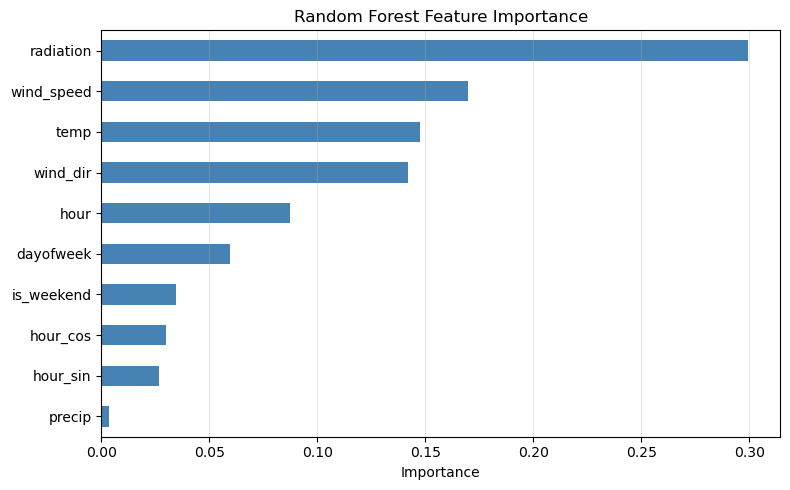

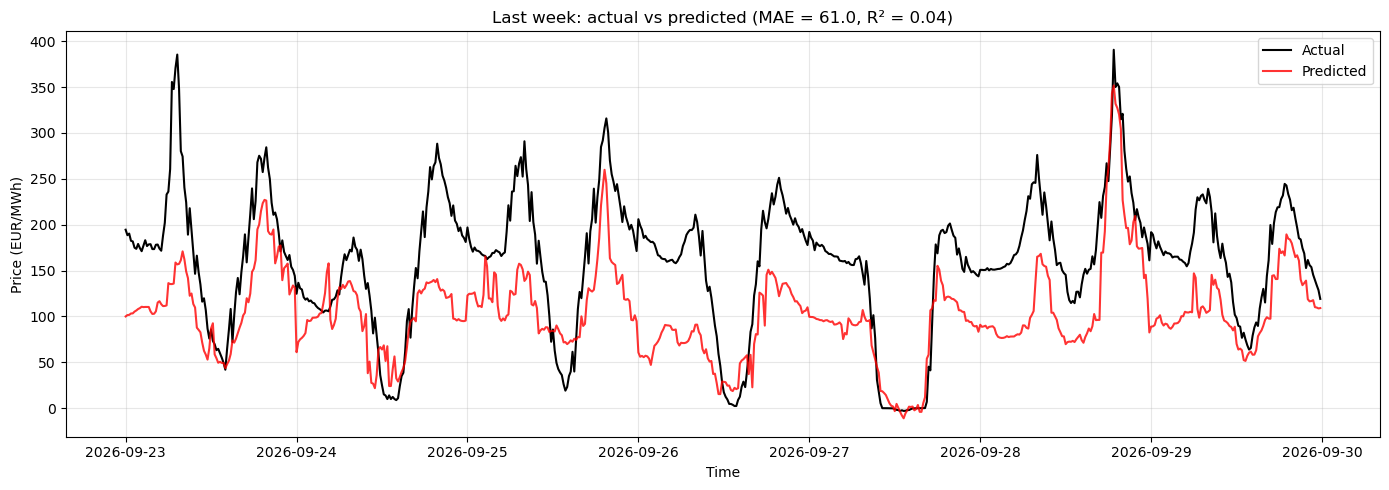

In [16]:
# ==========================================
# 5. Random Forest Price Prediction - Model 1
# ==========================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ---------- 5.1 Feature engineering ----------
df['hour']       = df.index.hour
df['dayofweek']  = df.index.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
df['hour_sin']   = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos']   = np.cos(2 * np.pi * df['hour'] / 24)

# radiation and sunshine are highly correlated (>0.80), keep only radiation
features = ['temp', 'wind_speed', 'radiation', 'wind_dir', 'precip',
            'hour', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos']
target   = 'price_de_lu'

data = df[features + [target]].dropna()
X, y = data[features], data[target]

# ---------- 5.2 Time-series split: last 7 days as test ----------
n_test = 96 * 7
X_train, X_test = X.iloc[:-n_test], X.iloc[-n_test:]
y_train, y_test = y.iloc[:-n_test], y.iloc[-n_test:]

# ---------- 5.3 Train ----------
model = RandomForestRegressor(n_estimators=200, max_depth=20,
                              n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ---------- 5.4 Metrics ----------
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(((y_test - y_pred) ** 2).mean())
r2   = r2_score(y_test, y_pred)

print("=" * 50)
print("  Prediction Performance (last 7 days)")
print("=" * 50)
print(f"  MAE  : {mae:.2f} EUR/MWh")
print(f"  RMSE : {rmse:.2f} EUR/MWh")
print(f"  R²   : {r2:.3f}")
print("=" * 50)

# ---------- 5.5 Feature importance ----------
imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importance (Model 1):")
print(imp.round(4).to_string())

# ---------- 5.6 Plot feature importance ----------
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot(kind='barh', ax=ax, color='steelblue')
ax.invert_yaxis()
ax.set_xlabel('Importance')
ax.set_title('Random Forest Feature Importance')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# ---------- 5.7 Actual vs predicted (last 7 days) ----------
test_times = data.index[-n_test:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_times, y_test.values, label='Actual', color='black', lw=1.5)
ax.plot(test_times, y_pred,       label='Predicted', color='red', lw=1.5, alpha=0.8)
ax.set_xlabel('Time')
ax.set_ylabel('Price (EUR/MWh)')
ax.set_title(f'Last week: actual vs predicted (MAE = {mae:.1f}, R² = {r2:.2f})')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# 5. Random Forest Price Prediction - Model 2
# ==========================================
# ---------- Lag features ----------
df['price_lag_1h'] = df['price_de_lu'].shift(4)
df['price_lag_1d'] = df['price_de_lu'].shift(96)
df['price_lag_7d'] = df['price_de_lu'].shift(96*7)
df['neighbor']     = df['price_neighbors']

# ---------- Feature list ----------
features = ['temp', 'wind_speed', 'radiation', 'wind_dir', 'precip',
            'hour', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos',
            'price_lag_1h', 'price_lag_1d', 'price_lag_7d', 'neighbor']
target   = 'price_de_lu'

data = df[features + [target]].dropna()
X, y = data[features], data[target]

n_test = 96 * 7
X_train, X_test = X.iloc[:-n_test], X.iloc[-n_test:]
y_train, y_test = y.iloc[:-n_test], y.iloc[-n_test:]

model = RandomForestRegressor(n_estimators=200, max_depth=20,
                              n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(((y_test - y_pred)**2).mean())
r2   = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f} EUR/MWh")
print(f"RMSE : {rmse:.2f} EUR/MWh")
print(f"R²   : {r2:.3f}")

imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importance (Model 2):")
print(imp.round(4).to_string())

MAE  : 12.97 EUR/MWh
RMSE : 19.26 EUR/MWh
R²   : 0.930

Feature importance (Model 2):
neighbor        0.9464
price_lag_1h    0.0249
temp            0.0048
price_lag_1d    0.0041
wind_speed      0.0038
hour_sin        0.0035
price_lag_7d    0.0032
wind_dir        0.0024
radiation       0.0023
hour            0.0015
hour_cos        0.0015
dayofweek       0.0013
is_weekend      0.0002
precip          0.0001


## Price Prediction: Feature Importance

Two Random Forest models were trained to assess the predictive value of weather variables.

### Model 1 : Weather + Time only

Using weather and time features only, the model achieves **R² = 0.04** on a held-out 7-day test set — indicating very limited predictive power. Feature importance correctly identifies solar radiation as the strongest weather driver (0.30), followed by wind speed (0.17) and temperature (0.15), consistent with the correlation analysis.

### Model 2 : Weather + Time + Lagged/Neighbor Prices

Adding lagged prices (1h, 1d, 7d) and neighbor-country prices raises R² to **0.93**. However, feature importance is overwhelmingly dominated by **neighbor-country prices (94.6%)**, with weather variables contributing less than 2% combined.

### Interpretation

Day-ahead prices are driven primarily by market factors — neighbor-country prices, price autocorrelation, demand, and fuel costs — that are not captured by weather alone. Weather explains the *direction* of price pressure but not the *magnitude* of day-to-day variation. Once market coupling is accounted for, weather effects are transmitted indirectly through neighbor prices rather than directly driving German prices.

**Conclusion:** Weather variables alone are insufficient for standalone price forecasting. However, the strong weather–price correlation (r = -0.50 for radiation) confirms that weather remains a physical driver of price formation.